<a href="https://colab.research.google.com/github/LuisManuelCatzoliSoriano/Simulaci-n_II/blob/main/Copia_de_imo_scraping_sheets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Web scraping: resultados individuales de la Olimpiada Internacional de Matemáticas (IMO) → Google Sheets

**Fuente:** [imo-official.org/results](https://www.imo-official.org/results/). El sitio oficial de la IMO publica, para cada edición desde 1959, la tabla con todos los participantes: país, rango, premio, puntos totales y la calificación (0 a 7) en cada uno de los seis problemas. Una página por año, por ejemplo [2024](https://www.imo-official.org/results/individual/year/2024/), con ~600 filas; las ediciones recientes tienen 590–670 participantes, así que con 9 años se pasan las 5,500 filas.

**Base de datos que se construye:** una fila por participante y año. Columnas: año, participante, país, código de país, rango, premio, puntos, P1–P6, puntos del día 1 (P1+P2+P3), del día 2 (P4+P5+P6) y número de problemas resueltos completos (calificación 7).

## Hipótesis

> **El orden de los problemas refleja su dificultad: dentro de cada día del examen, el puntaje medio decrece con el número del problema.**

El examen son dos días con tres problemas cada uno, que el jurado acomoda en orden creciente de dificultad planeada (P1 y P4 fáciles, P2 y P5 medios, P3 y P6 difíciles). Sea $\mu_k$ el puntaje medio del problema $k$. La hipótesis es

$$H_1:\ \mu_1 > \mu_2 > \mu_3 \quad\text{y}\quad \mu_4 > \mu_5 > \mu_6$$

contra la nula de que cada par consecutivo no difiere ($\mu_1 \le \mu_2$, etc.). Como cada participante contesta los seis problemas, los puntajes están pareados; se usa la prueba de Wilcoxon de rangos con signo (una cola) para cada par consecutivo del mismo día. De pilón se revisa si las medallas se reparten en la proporción 1:2:3 (oro:plata:bronce) que marca el reglamento, con una prueba $\chi^2$ por año.

**Cómo usarlo:** se cambia `N_OBJETIVO` (500 para probar, 5500 para la entrega), *Entorno de ejecución → Ejecutar todo*. Las librerías ya vienen en Colab.

## 1. Parámetros

## 2. Descarga de páginas

In [18]:
N_OBJETIVO = 25000
NOMBRE_SHEET = "IMO_Scraping_" + str(N_OBJETIVO)
ANIO_FINAL = 1983          # desde aquí el examen es de 6 problemas de 7 puntos

registros = []
fallidos = []
inicio_tiempo = time.time()
for anio in range(ANIO_INICIAL, ANIO_FINAL - 1, -1):
    if len(registros) >= N_OBJETIVO:
        break
    url = BASE + "/results/individual/year/" + str(anio) + "/"
    try:
        participantes = extraer_pagina(obtener_html(url), anio)
    except Exception as error:
        print("Error en", anio, "->", error)
        fallidos.append(anio)
        continue
    if len(participantes) == 0:
        print("IMO", anio, ": sin tabla reconocida")
        fallidos.append(anio)
        continue
    registros.extend(participantes)
    print(f"IMO {anio}: +{len(participantes):3d}  acumulado: {len(registros)}")
    time.sleep(PAUSA)

crudo = pd.DataFrame(registros).head(N_OBJETIVO)
print("\nFilas obtenidas:", len(crudo), "en", round(time.time() - inicio_tiempo), "segundos")
print("Años en la base:", crudo["anio"].min(), "a", crudo["anio"].max(), "(", crudo["anio"].nunique(), "años )")
print("Años con problema:", fallidos)

IMO 2026: +666  acumulado: 666
IMO 2025: +630  acumulado: 1296
IMO 2024: +609  acumulado: 1905
IMO 2023: +618  acumulado: 2523
IMO 2022: +589  acumulado: 3112
IMO 2021: +619  acumulado: 3731
IMO 2020: +616  acumulado: 4347
IMO 2019: +621  acumulado: 4968
IMO 2018: +594  acumulado: 5562
IMO 2017: +615  acumulado: 6177
IMO 2016: +602  acumulado: 6779
IMO 2015: +577  acumulado: 7356
IMO 2014: +560  acumulado: 7916
IMO 2013: +527  acumulado: 8443
IMO 2012: +547  acumulado: 8990
IMO 2011: +563  acumulado: 9553
IMO 2010: +516  acumulado: 10069
IMO 2009: +565  acumulado: 10634
IMO 2008: +535  acumulado: 11169
IMO 2007: +520  acumulado: 11689
IMO 2006: +498  acumulado: 12187
IMO 2005: +513  acumulado: 12700
IMO 2004: +486  acumulado: 13186
IMO 2003: +457  acumulado: 13643
IMO 2002: +479  acumulado: 14122
IMO 2001: +473  acumulado: 14595
IMO 2000: +461  acumulado: 15056
IMO 1999: +450  acumulado: 15506
IMO 1998: +419  acumulado: 15925
IMO 1997: +460  acumulado: 16385
IMO 1996: +424  acumulado: 

## 3. Extracción de la tabla

La tabla de cada año tiene las columnas `Contestant, Country, Rank, Award, Points, P1, P2, P3, P4, P5, P6` (los encabezados traen también la abreviatura, p. ej. `CountryCtry`, por eso se comparan con `startswith`). El país viene como bandera + nombre + código de tres letras entre paréntesis, p. ej. `Mexico (MEX)`; los participantes individuales sin delegación traen esa celda vacía.

In [32]:
def extraer_pagina(html, anio):
    soup = BeautifulSoup(html, "html.parser")

    # Se toma la tabla cuyo encabezado contiene P1 y P6
    tabla = None
    for t in soup.find_all("table"):
        celdas_encabezado = t.find_all("th")
        if len(celdas_encabezado) == 0:            # por si el encabezado viniera con <td> en vez de <th>
            celdas_encabezado = t.find("tr").find_all("td")
        textos = []
        for th in celdas_encabezado:
            textos.append(th.get_text("", strip=True))
        if "P1" in textos and "P6" in textos:
            tabla = t
            encabezados = textos
            break
    if tabla is None:
        return []

    # Se ubica cada columna por su encabezado (por si el sitio cambia el orden)
    posicion = {}
    for i, texto in enumerate(encabezados):
        if texto.startswith("Contestant"):
            posicion["participante"] = i
        elif texto.startswith("Country") or texto.startswith("Ctry"):
            posicion["pais"] = i
        elif texto.startswith("Rank") or texto.startswith("Rnk"):
            posicion["rango"] = i
        elif texto.startswith("Award") or texto.startswith("Awd"):
            posicion["premio"] = i
        elif texto.startswith("Points") or texto.startswith("Pts"):
            posicion["puntos"] = i
        elif re.fullmatch(r"P[1-6]", texto):
            posicion[texto] = i
    if len(posicion) < 11:        # si no se reconocieron todas, se usa el orden conocido
        nombres = ["participante", "pais", "rango", "premio", "puntos", "P1", "P2", "P3", "P4", "P5", "P6"]
        posicion = {}
        for i, nombre in enumerate(nombres):
            posicion[nombre] = i

    participantes = []
    for tr in tabla.find_all("tr"):
        celdas = tr.find_all("td")
        if len(celdas) < 11:          # se omite el encabezado (usa <th>) y filas incompletas
            continue
        registro = {"anio": anio}
        for nombre in posicion:
            registro[nombre] = celdas[posicion[nombre]].get_text(" ", strip=True)

        # País: "Mexico (MEX)" -> nombre y código; celda vacía -> participante individual
        texto_pais = registro["pais"]
        coincidencia = re.search(r"\(([A-Z]{3})\)", texto_pais)
        if coincidencia is not None:
            registro["pais_codigo"] = coincidencia.group(1)
            registro["pais"] = texto_pais[:coincidencia.start()].strip()
        else:
            registro["pais_codigo"] = ""

        # Liga al perfil del participante, por si se quiere consultar después
        enlace = celdas[posicion["participante"]].find("a", href=True)
        if enlace is not None:
            registro["url"] = BASE + enlace["href"]
        else:
            registro["url"] = ""
        participantes.append(registro)
    return participantes

# Prueba rápida con la edición más reciente
prueba = extraer_pagina(obtener_html(BASE + "/results/individual/year/" + str(ANIO_INICIAL) + "/"), ANIO_INICIAL)
print(len(prueba), "participantes en la IMO", ANIO_INICIAL)
prueba[:3]

666 participantes en la IMO 2026


[{'anio': 2026,
  'participante': 'Leyan Deng',
  'pais': "People's Republic of China CHN",
  'rango': '1',
  'premio': 'G',
  'puntos': '42',
  'P1': '7',
  'P2': '7',
  'P3': '7',
  'P4': '7',
  'P5': '7',
  'P6': '7',
  'pais_codigo': '',
  'url': 'https://www.imo-official.org/results/contestant/35092/'},
 {'anio': 2026,
  'participante': 'Che Liu',
  'pais': "People's Republic of China CHN",
  'rango': '1',
  'premio': 'G',
  'puntos': '42',
  'P1': '7',
  'P2': '7',
  'P3': '7',
  'P4': '7',
  'P5': '7',
  'P6': '7',
  'pais_codigo': '',
  'url': 'https://www.imo-official.org/results/contestant/35751/'},
 {'anio': 2026,
  'participante': 'Bolun Zhang',
  'pais': "People's Republic of China CHN",
  'rango': '1',
  'premio': 'G',
  'puntos': '42',
  'P1': '7',
  'P2': '7',
  'P3': '7',
  'P4': '7',
  'P5': '7',
  'P6': '7',
  'pais_codigo': '',
  'url': 'https://www.imo-official.org/results/contestant/35747/'}]

In [33]:
# Se recorren las ediciones de la más reciente hacia atrás hasta juntar N_OBJETIVO filas
registros = []
errores = 0
inicio_tiempo = time.time()
for anio in range(ANIO_INICIAL, 1958, -1):
    if len(registros) >= N_OBJETIVO:
        break
    url = BASE + "/results/individual/year/" + str(anio) + "/"
    try:
        participantes = extraer_pagina(obtener_html(url), anio)
    except Exception as error:
        print("Error en", anio, "->", error)
        errores += 1
        if errores >= 3:              # si el sitio no responde, no tiene sentido seguir
            break
        continue
    registros.extend(participantes)
    print(f"IMO {anio}: +{len(participantes):3d}  acumulado: {len(registros)}")
    time.sleep(PAUSA)

crudo = pd.DataFrame(registros).head(N_OBJETIVO)    # se recorta exactamente a N_OBJETIVO
print("Filas obtenidas:", len(crudo), "en", round(time.time() - inicio_tiempo), "segundos")
crudo.head()

IMO 2026: +666  acumulado: 666
IMO 2025: +630  acumulado: 1296
IMO 2024: +609  acumulado: 1905
IMO 2023: +618  acumulado: 2523
IMO 2022: +589  acumulado: 3112
IMO 2021: +619  acumulado: 3731
IMO 2020: +616  acumulado: 4347
IMO 2019: +621  acumulado: 4968
IMO 2018: +594  acumulado: 5562
IMO 2017: +615  acumulado: 6177
IMO 2016: +602  acumulado: 6779
IMO 2015: +577  acumulado: 7356
IMO 2014: +560  acumulado: 7916
IMO 2013: +527  acumulado: 8443
IMO 2012: +547  acumulado: 8990
IMO 2011: +563  acumulado: 9553
IMO 2010: +516  acumulado: 10069
IMO 2009: +565  acumulado: 10634
IMO 2008: +535  acumulado: 11169
IMO 2007: +520  acumulado: 11689
IMO 2006: +498  acumulado: 12187
IMO 2005: +513  acumulado: 12700
IMO 2004: +486  acumulado: 13186
IMO 2003: +457  acumulado: 13643
IMO 2002: +479  acumulado: 14122
IMO 2001: +473  acumulado: 14595
IMO 2000: +461  acumulado: 15056
IMO 1999: +450  acumulado: 15506
IMO 1998: +419  acumulado: 15925
IMO 1997: +460  acumulado: 16385
IMO 1996: +424  acumulado: 

,anio,participante,pais,rango,premio,puntos,P1,P2,P3,P4,P5,P6,pais_codigo,url
0,2026,Leyan Deng,People's Republic of China CHN,1,G,42,7,7,7,7,7,7,,https://www.imo-official.org/results/contestan...
1,2026,Che Liu,People's Republic of China CHN,1,G,42,7,7,7,7,7,7,,https://www.imo-official.org/results/contestan...
2,2026,Bolun Zhang,People's Republic of China CHN,1,G,42,7,7,7,7,7,7,,https://www.imo-official.org/results/contestan...
3,2026,Hyeonjun Lee,Republic of Korea KOR,1,G,42,7,7,7,7,7,7,,https://www.imo-official.org/results/contestan...
4,2026,Alex Chui,United Kingdom UNK,1,G,42,7,7,7,7,7,7,,https://www.imo-official.org/results/contestan...


## 4. Limpieza

Rango, puntos y P1–P6 se convierten a números; si alguna celda viniera vacía queda como `NaN`. El premio viene como `G`, `S`, `B`, `HM` (mención honorífica) o vacío, y se traduce a una columna `medalla`. Se agregan los puntos por día y el número de problemas resueltos completos (calificación 7).

In [34]:
df = crudo.copy()

problemas = ["P1", "P2", "P3", "P4", "P5", "P6"]
for col in ["rango", "puntos"] + problemas:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Las columnas sin valores faltantes se dejan como enteros
for col in ["rango", "puntos"] + problemas:
    if df[col].isna().sum() == 0:
        df[col] = df[col].astype(int)

traduccion = {"G": "Oro", "S": "Plata", "B": "Bronce", "HM": "Mención honorífica", "": "Sin premio"}
medallas = []
for premio in df["premio"]:
    medallas.append(traduccion.get(premio, premio))
df["medalla"] = medallas

df["dia1"] = df["P1"] + df["P2"] + df["P3"]
df["dia2"] = df["P4"] + df["P5"] + df["P6"]
df["resueltos"] = (df[problemas] == 7).sum(axis=1)

df = df[["anio", "participante", "pais", "pais_codigo", "rango", "premio", "medalla", "puntos",
         "P1", "P2", "P3", "P4", "P5", "P6", "dia1", "dia2", "resueltos", "url"]]
print(df.shape)
print("Celdas vacías por columna:")
print(df.isna().sum()[df.isna().sum() > 0])
df.head(10)

(23003, 18)
Celdas vacías por columna:
rango      29
P1       1071
P2       1071
P3       1071
P4       1071
P5       1071
P6       1071
dia1     1071
dia2     1071
dtype: int64


,anio,participante,pais,pais_codigo,rango,premio,medalla,puntos,P1,P2,P3,P4,P5,P6,dia1,dia2,resueltos,url
0,2026,Leyan Deng,People's Republic of China CHN,,1.0,G,Oro,42,7.0,7.0,7.0,7.0,7.0,7.0,21.0,21.0,6,https://www.imo-official.org/results/contestan...
1,2026,Che Liu,People's Republic of China CHN,,1.0,G,Oro,42,7.0,7.0,7.0,7.0,7.0,7.0,21.0,21.0,6,https://www.imo-official.org/results/contestan...
2,2026,Bolun Zhang,People's Republic of China CHN,,1.0,G,Oro,42,7.0,7.0,7.0,7.0,7.0,7.0,21.0,21.0,6,https://www.imo-official.org/results/contestan...
3,2026,Hyeonjun Lee,Republic of Korea KOR,,1.0,G,Oro,42,7.0,7.0,7.0,7.0,7.0,7.0,21.0,21.0,6,https://www.imo-official.org/results/contestan...
4,2026,Alex Chui,United Kingdom UNK,,1.0,G,Oro,42,7.0,7.0,7.0,7.0,7.0,7.0,21.0,21.0,6,https://www.imo-official.org/results/contestan...
5,2026,Liam Reddy,United States of America USA,,1.0,G,Oro,42,7.0,7.0,7.0,7.0,7.0,7.0,21.0,21.0,6,https://www.imo-official.org/results/contestan...
6,2026,Alexander Wang,United States of America USA,,1.0,G,Oro,42,7.0,7.0,7.0,7.0,7.0,7.0,21.0,21.0,6,https://www.imo-official.org/results/contestan...
7,2026,Arina Prokudina,Russian Federation RUS,,8.0,G,Oro,41,7.0,7.0,6.0,7.0,7.0,7.0,20.0,21.0,5,https://www.imo-official.org/results/contestan...
8,2026,Andrey Shishko,Russian Federation RUS,,9.0,G,Oro,39,7.0,7.0,4.0,7.0,7.0,7.0,18.0,21.0,5,https://www.imo-official.org/results/contestan...
9,2026,Boyang Brian Xiao,Singapore SGP,,9.0,G,Oro,39,7.0,7.0,4.0,7.0,7.0,7.0,18.0,21.0,5,https://www.imo-official.org/results/contestan...


In [35]:
df.describe()

,anio,rango,puntos,P1,P2,P3,P4,P5,P6,dia1,dia2,resueltos
count,23003.000000,22974.000000,23003.000000,21932.000000,21932.000000,21932.000000,21932.000000,21932.000000,21932.000000,21932.000000,21932.000000,23003.000000
mean,2004.279877,225.206755,16.055210,4.418703,2.698432,1.199252,4.119369,2.487917,0.933522,8.316387,7.540808,1.454332
std,15.752120,160.972562,10.469547,2.882165,2.903769,2.212681,2.932256,2.854119,2.016519,5.736670,5.667156,1.459043
min,1959.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1994.000000,83.000000,8.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,3.000000,2.000000,0.000000
50%,2007.000000,198.000000,15.000000,6.000000,1.000000,0.000000,5.000000,1.000000,0.000000,8.000000,7.000000,1.000000
75%,2017.000000,350.000000,23.000000,7.000000,7.000000,1.000000,7.000000,6.000000,1.000000,13.000000,12.000000,2.000000
max,2026.000000,647.000000,46.000000,8.000000,8.000000,9.000000,7.000000,8.000000,9.000000,21.000000,22.000000,6.000000


In [36]:
# Respaldo local en CSV (se puede descargar desde el panel de archivos de Colab)
df.to_csv("imo_resultados_" + str(N_OBJETIVO) + ".csv", index=False)
print("CSV guardado")

CSV guardado


## 5. Prueba de la hipótesis

Primero se ve el puntaje medio de cada problema (en total y por año). Después, para cada par de problemas consecutivos del mismo día se aplica la prueba de Wilcoxon de rangos con signo, de una cola: $H_0: \mu_a \le \mu_b$ vs $H_1: \mu_a > \mu_b$. Son datos pareados porque cada participante contesta los seis problemas.

In [37]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

completos = df.dropna(subset=problemas)

print("Puntaje medio por problema (0 a 7):")
print(completos[problemas].mean().round(2).to_string())
print("\nPor año:")
medias_anio = completos.groupby("anio")[problemas].mean().round(2)
print(medias_anio.to_string())

print("\nPrueba de Wilcoxon (una cola) por pares consecutivos del mismo día:")
pares = [("P1", "P2"), ("P2", "P3"), ("P4", "P5"), ("P5", "P6")]
rechazos = 0
for a, b in pares:
    resultado = stats.wilcoxon(completos[a], completos[b], alternative="greater")
    print(f"  {a} > {b}: medias {completos[a].mean():.2f} vs {completos[b].mean():.2f},  p-valor = {resultado.pvalue:.2e}")
    if resultado.pvalue < 0.05:
        rechazos += 1
if rechazos == len(pares):
    print("Se rechaza H0 en los cuatro pares al 5%: el puntaje medio decrece con el número del problema en ambos días.")
else:
    print("No se rechaza H0 en", len(pares) - rechazos, "de los pares: el orden planeado no se cumple en todos los casos.")

Puntaje medio por problema (0 a 7):
P1    4.42
P2    2.70
P3    1.20
P4    4.12
P5    2.49
P6    0.93

Por año:
        P1    P2    P3    P4    P5    P6
anio                                    
1959  2.78  6.11  4.22  2.11  1.44  2.56
1960  3.80  2.60  1.20  3.60  1.80  1.70
1961  3.22  3.11  2.56  2.67  3.00  1.89
1962  5.41  4.53  4.88  3.94  4.18  2.24
1963  3.50  3.25  1.94  1.38  2.38  6.06
1964  5.24  3.29  5.06  2.47  3.65  5.82
1965  2.74  2.70  4.03  4.19  3.79  2.75
1966  5.33  6.04  4.67  4.70  5.00  7.33
1967  3.73  4.05  3.32  4.24  3.57  5.05
1968  4.43  6.07  4.04  3.57  4.59  5.32
1969  2.55  4.37  4.20  2.27  4.18  2.44
1970  3.49  5.94  1.51  4.94  3.37  2.40
1971  2.32  1.89  0.79  2.50  1.39  0.50
1972  3.06  3.76  2.33  4.91  2.82  3.88
1973  2.58  2.69  3.99  3.86  3.38  1.13
1974  4.51  3.76  2.81  5.06  3.10  3.10
1975  4.73  4.16  4.05  3.49  2.81  2.80
1976  2.61  1.94  3.12  3.76  1.09  4.59
1977  5.33  2.91  3.31  3.27  3.24  3.11
1978  4.57  2.48  3.25  4.2

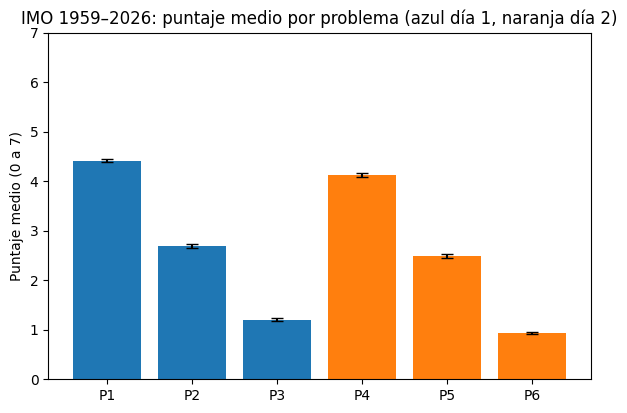

In [38]:
# Gráfica: puntaje medio por problema con su error estándar
medias = completos[problemas].mean()
errores = completos[problemas].std() / np.sqrt(len(completos))
colores = ["tab:blue"] * 3 + ["tab:orange"] * 3

plt.figure(figsize=(7, 4.5))
plt.bar(problemas, medias, yerr=1.96 * errores, color=colores, capsize=4)
plt.ylabel("Puntaje medio (0 a 7)")
plt.title("IMO " + str(completos["anio"].min()) + "–" + str(completos["anio"].max()) +
          ": puntaje medio por problema (azul día 1, naranja día 2)")
plt.ylim(0, 7)
plt.show()

## 6. De pilón: reparto de medallas y México

El reglamento de la IMO dice que oro, plata y bronce deben repartirse aproximadamente en proporción 1:2:3 entre quienes reciben medalla. Se prueba por año con una $\chi^2$ de bondad de ajuste ($H_0$: proporciones 1/6, 1/3, 1/2). Y se resume el desempeño de la delegación mexicana.

In [39]:
print("Año   Oro  Plata  Bronce   p-valor (chi2 para 1:2:3)")
for anio, sub in df.groupby("anio"):
    conteo = [(sub["premio"] == "G").sum(), (sub["premio"] == "S").sum(), (sub["premio"] == "B").sum()]
    total = sum(conteo)
    if total == 0:
        continue
    esperado = [total / 6, total / 3, total / 2]
    chi = stats.chisquare(conteo, f_exp=esperado)
    print(f"{anio}  {conteo[0]:4d}  {conteo[1]:5d}  {conteo[2]:6d}   {chi.pvalue:.3f}")

mexico = df[df["pais_codigo"] == "MEX"]
if len(mexico) > 0:
    print("\nMéxico por año (participantes, puntos promedio, puntos totales, medallas):")
    resumen = mexico.groupby("anio").agg(participantes=("puntos", "size"), promedio=("puntos", "mean"),
                                         total=("puntos", "sum"), medallas=("premio", lambda s: (s.isin(["G", "S", "B"])).sum()))
    print(resumen.round(2).to_string())
    print("\nMejores resultados mexicanos en la muestra:")
    print(mexico.sort_values("puntos", ascending=False)[["anio", "participante", "rango", "medalla", "puntos"]].head(5).to_string(index=False))

Año   Oro  Plata  Bronce   p-valor (chi2 para 1:2:3)
1959     3      3       5   0.635
1960     4      4       4   0.264
1961     3      4       4   0.554
1962     4     12      15   0.760
1963     7     11      17   0.867
1964     7      9      19   0.615
1965     8     12      17   0.713
1966    13     15      11   0.005
1967    11     14      26   0.529
1968    22     22      20   0.000
1969     3     20      21   0.103
1970     7     11      40   0.014
1971     7     12      29   0.338
1972     8     16      30   0.717
1973     5     15      48   0.003
1974    10     24      37   0.839
1975     8     25      36   0.521
1976     9     28      45   0.368
1977    13     29      35   0.686
1978     5     20      38   0.118
1979     8     32      42   0.205
1981    36     37      30   0.000
1982    10     20      31   0.992
1983     9     27      57   0.060
1984    14     35      49   0.779
1985    14     35      52   0.750
1986    18     41      48   0.505
1987    22     42      56   0

## 7. Guardar en Google Sheets

Al correr la celda aparece una ventana para iniciar sesión con tu cuenta de Google y dar permisos a Colab. El archivo se crea en la raíz de tu Drive; si ya existe uno con el mismo nombre se sobrescribe.

In [40]:
from google.colab import auth
from google.auth import default
import gspread

# Se autoriza la cuenta de Google y se crea el cliente de gspread
auth.authenticate_user()
credenciales, _ = default()
gc = gspread.authorize(credenciales)

# Se abre el archivo si ya existe; si no, se crea
try:
    sh = gc.open(NOMBRE_SHEET)
except gspread.SpreadsheetNotFound:
    sh = gc.create(NOMBRE_SHEET)
    sh.sheet1.update_title("imo")      # se renombra la hoja que Google crea por defecto

def escribir_hoja(sh, titulo, datos):
    # Se convierte el DataFrame en lista de listas (encabezado + filas); NaN vacíos
    datos = datos.copy()
    valores = [list(datos.columns)] + datos.fillna("").values.tolist()
    # Se reutiliza la hoja si ya existe (y se limpia); si no, se crea
    try:
        ws = sh.worksheet(titulo)
        ws.clear()
        ws.resize(rows=len(valores), cols=len(valores[0]))
    except gspread.WorksheetNotFound:
        ws = sh.add_worksheet(title=titulo, rows=len(valores), cols=len(valores[0]))
    ws.update(values=valores, range_name="A1", value_input_option="USER_ENTERED")
    print(titulo + ":", len(valores) - 1, "filas x", len(valores[0]), "columnas")
    return ws

escribir_hoja(sh, "imo", df)                                        # base principal: N filas
escribir_hoja(sh, "medias_por_anio", medias_anio.reset_index())     # extra: puntaje medio por problema y año
print("Listo:", sh.url)

imo: 23003 filas x 18 columnas
medias_por_anio: 67 filas x 7 columnas
Listo: https://docs.google.com/spreadsheets/d/1UwYyZY8fORvJm07RSu4YEWK3KGqT8bs1aPIp-EzQaR0


## Notas

- Para la entrega: `N_OBJETIVO = 5500` y *Ejecutar todo*; son 9 ediciones (2026 a 2018), menos de un minuto. Se crea otro archivo (`IMO_Scraping_5500`), el de 500 no se toca. Con `N_OBJETIVO = 25000` se baja la historia completa desde 1959 (el ciclo se detiene solo).
- Las ediciones antiguas tienen menos participantes (52 en 1959) y en algunos años hubo 7 problemas o puntajes distintos de 0–7; la hipótesis se plantea con las ediciones recientes.
- Algunos nombres aparecen como `*** ***` porque el participante pidió no ser publicado; se dejan así.

Años en la serie: 1983 a 2026 ( 44 años )


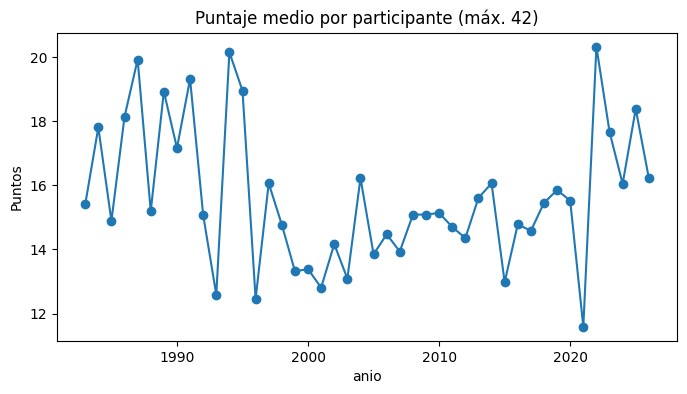

d = 0 -> p-valor ADF = 0.2839 (estacionaria si p < 0.05)
d = 1 -> p-valor ADF = 0.0 (estacionaria si p < 0.05)
d = 2 -> p-valor ADF = 0.1369 (estacionaria si p < 0.05)
Mejor orden por AIC: (2, 1, 1)  AIC = 191.66
RMSE ARIMA: 3.42 | RMSE ingenuo: 6.33
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4594      0.224     -2.047      0.041      -0.899      -0.020
ar.L2         -0.3988      0.177     -2.259      0.024      -0.745      -0.053
ma.L1         -0.4584      0.260     -1.763      0.078      -0.968       0.051
sigma2         4.0761      0.949      4.296      0.000       2.217       5.936
 anio  proyeccion  inferior_95  superior_95
 2027       16.81        12.85        20.77
 2028       17.40        13.43        21.37
 2029       16.90        12.90        20.89
 2030       16.89        12.50        21.28
 2031       17.10        12.56        21.63


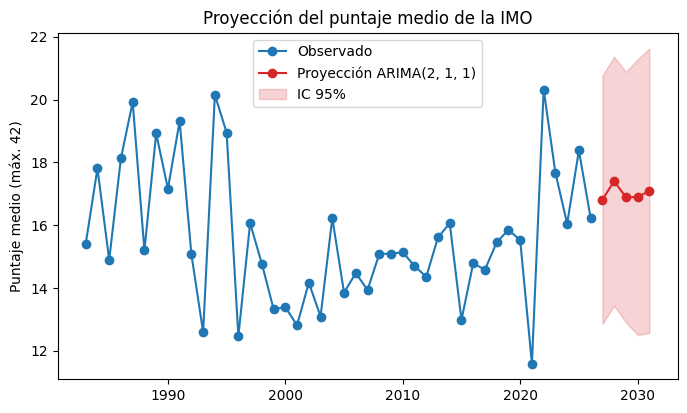

clase
3    10269
2     5045
1     3425
0     1703
Name: count, dtype: int64
Línea base (clase más frecuente): 0.502
Regresión logística: 0.683
Red neuronal (MLP): 0.684


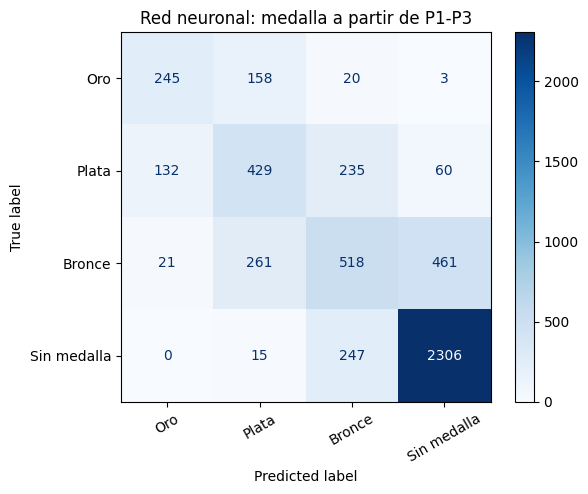

In [41]:
# =====================================================================
# PUNTO 5: ARIMA + PROYECCIÓN
# Requisito: haber corrido el scraping con N_OBJETIVO = 25000
# (pega cada bloque "# %%" como una celda nueva, después de la limpieza)
# =====================================================================

# %% Celda 1: serie anual (puntaje medio por participante)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
import warnings
warnings.filterwarnings("ignore")

# Desde 1983 el examen es de 6 problemas de 7 puntos (máximo 42), así la serie es comparable
base = df[df["anio"] >= 1983].dropna(subset=["puntos"])
serie = base.groupby("anio")["puntos"].mean().sort_index()
print("Años en la serie:", serie.index.min(), "a", serie.index.max(), "(", len(serie), "años )")
serie.plot(marker="o", figsize=(8, 4), title="Puntaje medio por participante (máx. 42)")
plt.ylabel("Puntos")
plt.show()

# %% Celda 2: estacionariedad (ADF) para decidir cuántas diferencias usar
for d in range(3):
    s = serie.diff(d).dropna() if d > 0 else serie
    p = adfuller(s)[1]
    print("d =", d, "-> p-valor ADF =", round(p, 4), "(estacionaria si p < 0.05)")

# %% Celda 3: elegir (p,d,q) con el menor AIC
mejor = None
for p in range(3):
    for d in range(3):
        for q in range(3):
            try:
                ajuste = ARIMA(serie.values, order=(p, d, q)).fit()
            except Exception:
                continue
            if mejor is None or ajuste.aic < mejor[0]:
                mejor = (ajuste.aic, (p, d, q))
orden = mejor[1]
print("Mejor orden por AIC:", orden, " AIC =", round(mejor[0], 2))

# %% Celda 4: validación (se entrena sin los últimos 5 años y se compara contra un modelo ingenuo)
h = 5
entrenamiento, prueba = serie.values[:-h], serie.values[-h:]
pred = ARIMA(entrenamiento, order=orden).fit().forecast(h)
ingenuo = np.repeat(entrenamiento[-1], h)          # "el próximo año igual que el último"
rmse_arima = np.sqrt(np.mean((pred - prueba) ** 2))
rmse_ingenuo = np.sqrt(np.mean((ingenuo - prueba) ** 2))
print("RMSE ARIMA:", round(rmse_arima, 2), "| RMSE ingenuo:", round(rmse_ingenuo, 2))

# %% Celda 5: ajuste final y proyección a 5 años con intervalo al 95%
modelo = ARIMA(serie.values, order=orden).fit()
print(modelo.summary().tables[1])

f = modelo.get_forecast(h)
proy = f.predicted_mean
ic = f.conf_int(alpha=0.05)
anios_futuros = np.arange(serie.index.max() + 1, serie.index.max() + 1 + h)

tabla = pd.DataFrame({"anio": anios_futuros, "proyeccion": proy.round(2),
                      "inferior_95": ic[:, 0].round(2), "superior_95": ic[:, 1].round(2)})
print(tabla.to_string(index=False))

plt.figure(figsize=(8, 4.5))
plt.plot(serie.index, serie.values, marker="o", label="Observado")
plt.plot(anios_futuros, proy, marker="o", color="tab:red", label="Proyección ARIMA" + str(orden))
plt.fill_between(anios_futuros, ic[:, 0], ic[:, 1], color="tab:red", alpha=0.2, label="IC 95%")
plt.ylabel("Puntaje medio (máx. 42)")
plt.title("Proyección del puntaje medio de la IMO")
plt.legend()
plt.show()


# =====================================================================
# PUNTO 6: RED NEURONAL (y de paso Clasificación, punto 2)
# Predecir la medalla usando SOLO los problemas del día 1 (P1-P3),
# porque con el puntaje total sería trivial (la medalla se define por cortes de puntos).
# =====================================================================

# %% Celda 6: datos
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

datos = df[df["anio"] >= 1983].dropna(subset=["P1", "P2", "P3"]).copy()
datos["clase"] = datos["premio"].map({"G": "Oro", "S": "Plata", "B": "Bronce"}).fillna("Sin medalla")
X = datos[["P1", "P2", "P3"]]
codigos = {"Oro": 0, "Plata": 1, "Bronce": 2, "Sin medalla": 3}
y = datos["clase"].map(codigos)
print(y.value_counts())

X_ent, X_prueba, y_ent, y_prueba = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# %% Celda 7: red neuronal vs. regresión logística vs. línea base
red = make_pipeline(StandardScaler(),
                    MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=1000, early_stopping=True, random_state=42))
red.fit(X_ent, y_ent)

logistica = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logistica.fit(X_ent, y_ent)

base_acc = (y_prueba == y_ent.mode()[0]).mean()    # siempre predecir la clase más frecuente
print("Línea base (clase más frecuente):", round(base_acc, 3))
print("Regresión logística:", round(accuracy_score(y_prueba, logistica.predict(X_prueba)), 3))
print("Red neuronal (MLP):", round(accuracy_score(y_prueba, red.predict(X_prueba)), 3))

# %% Celda 8: matriz de confusión de la red neuronal
nombres = ["Oro", "Plata", "Bronce", "Sin medalla"]
cm = confusion_matrix(y_prueba, red.predict(X_prueba), labels=[0, 1, 2, 3])
ConfusionMatrixDisplay(cm, display_labels=nombres).plot(cmap="Blues", xticks_rotation=30)
plt.title("Red neuronal: medalla a partir de P1-P3")
plt.show()